# Quickstart 3: three sources, the search

**A star has a faint companion inside one FWHM, which moves, and a brighter neighbour 250 mas away. The steps
of [notebook 2](2_binary_backprojected_seed.ipynb) assume one companion: the highest peak of the map. Here the
lines of two sources are mixed, and the number of sources is not known. The search adds the sources one at a
time. Each step of it is called a rung:**

1. **propose**: the highest peak of the map of the lines that no accepted source explains;
2. **score**: the joint fit of all windows with the candidate, against the fit without it;
3. **test**: the gain must be above a threshold that noise alone reaches in 1 % of the cases;
4. **assign**: the lines of the accepted source leave the pool; then the next rung.

The scene is that of the paper's Figure 4 (Sect. 5.2;
[`paper/fig4_contaminated_binary.ipynb`](../paper/fig4_contaminated_binary.ipynb)).

| block | task | call | paper |
|---|---|---|---|
| 1 | the data: windows and detections | `sim.Scene`, `sim.simulate_campaign`, `red.reduce_campaign` | Sect. 2, Eq. 8; Sect. 5.2 |
| 2 | the map of all the lines | `bp.backprojection_map` | Sect. 3.3, Eq. 13; Fig. 4 |
| 3 | why one seed is not enough | `dyn.clean_detection_set` | Sect. 5 |
| 4 | the threshold | `thr.lrt_threshold` | Sect. 5.1 |
| 5 | rung 0, propose | `search.next_peak` | Sect. 5.1, stage 2 |
| 6 | rung 0, score | `search.lambda_rung` | Sect. 5.1, stage 2; Eq. 18 |
| 7 | rung 0, test | — | Sect. 5.1, stage 2 |
| 8 | rung 0, assign | `ins.project_al` | Sect. 5.1, stage 2; Eq. 17 |
| 9 | rung 1, the skipped refinement, and the end of the search | `search.next_peak`, `search.lambda_rung`, `dyn.clean_detection_set` | Sect. 5.1, 5.2 |
| 10 | the search in one call | `search.map_ladder`, `search.describe` | Sect. 5.1 |
| 11 | the measurement | `joint.fit_joint` | Sect. 5.1, stage 3; Eq. 18 |
| 12 | a source known from a catalogue | `joint.fit_joint` with `prior` | Sect. 4.3, Eq. 19 |
| 13 | the companions relative to the primary | `joint.polar_elements` | Sect. 5.2 |
| 14 | the checks, and the truth | — | Sect. 5.2 |

**The series.** [1](1_sinogram_fit.ipynb): the sinogram fit. [2](2_binary_backprojected_seed.ipynb): a
binary, the backprojected seed and the joint fit. 3 (this notebook).

**Conventions** ([`docs/conventions.md`](../../docs/conventions.md)): as in notebooks 1 and 2. A parameter
vector holds one block (Δα\*, Δδ, μα\*, μδ) per source, in mas and mas/yr; with a free primary, the
primary's block is first.

In [1]:
# the imports: numpy, matplotlib, and the scanlib modules; every scanlib call below carries its module's name
import numpy as np
import matplotlib.pyplot as plt

from scanlib import instrument as ins      # the instrument: sampling, LSF, the along-scan projection (Eq. 9)
from scanlib import noise                  # the noise model of a window
from scanlib import scanlaw                # scan angles, epochs and parallax factors
from scanlib import simulation as sim      # synthetic scenes and their windows
from scanlib import reduction as red       # one window, or a campaign, reduced to detections
from scanlib import backprojection as bp   # the triangulation map and its peak
from scanlib import dynamics as dyn        # the fits to the detections (the sinogram fits)
from scanlib import joint                  # the joint fit of all windows, and its helpers
from scanlib import search                 # the search for several sources (the map ladder)
from scanlib import thresholds as thr      # the threshold of the search, Lambda_c

In [2]:
# the plot style of the paper's figures, and the axis labels of a sky map
plt.rcParams.update({"font.size": 10.0, "axes.linewidth": 0.5, "xtick.labelsize": 9.0, "ytick.labelsize": 9.0,
                     "xtick.direction": "in", "ytick.direction": "in", "legend.frameon": False, "legend.fontsize": 8.0})
ACCENT, ACCENT_2 = "tomato", "dodgerblue"
EAST, NORTH = r"$\Delta\alpha^{*}$  [mas]   (East $\leftarrow$)", r"$\Delta\delta$  [mas]"

In [3]:
# a helper for the plots: the two ends of a detection's line on the sky
def sky_line(psi_i, eta_i, half=500.0):
    """The ends (dra*, ddec) of the line dra* sin(psi) + ddec cos(psi) = eta (Eq. 10), `half` mas each way.

    Inputs
        psi_i   the scan angle of the detection [rad]
        eta_i   its position along the scan [mas]
        half    half the length of the line that is drawn [mas]
    Returns an array of shape (2, 2): row 0 holds the dra* of the two ends, row 1 their ddec [mas]"""
    foot = eta_i * np.array([np.sin(psi_i), np.cos(psi_i)])        # the point of the line nearest the origin
    along = np.array([np.cos(psi_i), -np.sin(psi_i)])              # the direction of the line
    return np.array([foot - half * along, foot + half * along]).T  # .T: row 0 is dra*, row 1 is ddec

## 1. The data

*Paper: Sect. 2 (the windows), Eq. 8 (the detections); Sect. 5.2 (the scene).* As in notebooks 1 and 2, with
three sources. `sim.Scene` takes the positions, the fluxes and the proper motions of all the sources, the
primary first.

In [4]:
# the instrument and the scan law (notebook 1, blocks 1 and 2)
inst = ins.Instrument.gaussian(fwhm_mas=100.0, pitch_mas=59.0, n_samples=18, margins=ins.TOY_MARGINS)
psi, tau = scanlaw.load_scan_law(scanlaw.PLEIADES)

print(f"{psi.size} transits over {tau.max() - tau.min():.1f} yr")

47 transits over 5.1 yr


In [5]:
# the truth. B: 75 mas from the primary at position angle 110 deg, 0.2 of its flux, moving 8 mas/yr.
# C: 250 mas away at position angle 300 deg, 0.3 of the primary's flux, at rest
pa_B = np.deg2rad(110.0)                                            # the position angles [rad], from north through east
pa_C = np.deg2rad(300.0)
TRUE_B = 75.0 * np.array([np.sin(pa_B), np.cos(pa_B)])              # (dra*, ddec) [mas] at the reference epoch
TRUE_C = 250.0 * np.array([np.sin(pa_C), np.cos(pa_C)])
TRUE_PM_B = 8.0 * np.array([np.cos(pa_B), -np.sin(pa_B)])           # [mas/yr], across the line to the primary
scene = sim.Scene(np.array([[0.0, 0.0], TRUE_B, TRUE_C]), sim.PRIMARY_FLUX * np.array([1.0, 0.2, 0.3]),
                  pm=np.array([[0.0, 0.0], TRUE_PM_B, [0.0, 0.0]]))

print("B:", TRUE_B.round(1).tolist(), "mas, moving", TRUE_PM_B.round(2).tolist(), "mas/yr;  C:",
      TRUE_C.round(1).tolist(), "mas")

B: [70.5, -25.7] mas, moving [-2.74, -7.52] mas/yr;  C: [-216.5, 125.0] mas


In [6]:
# the noise model (a G = 16 primary), the zero point of each window, and the 47 windows with their sigma
SEED = 20260929                                                     # the noise draw of the paper's Figure 4
# noise.gaia_like: the noise of a G = 16 primary whose total flux is sim.PRIMARY_FLUX, in the windows' flux units
# (notebook 1, block 3, explains the units)
noise_model = noise.gaia_like(16.0, sim.PRIMARY_FLUX)
# rng_zero_points: the zero points' own stream; its seed is [the noise seed, the label 3 of this stream].
# rng_noise: the generator of the windows' noise; its seed is SEED alone
rng_zero_points = np.random.default_rng([SEED, 3])
eta0 = sim.random_zero_points(rng_zero_points, psi.size, inst)
rng_noise = np.random.default_rng(SEED)
# sim.simulate_campaign also returns the sources' true positions along the scan (dropped here, the name _)
windows, sigma, _ = sim.simulate_campaign(scene, (psi, tau), rng_noise, inst, noise_model, eta0=eta0)
windows = np.asarray(windows)                    # one array (transits, samples) in place of a list of windows
sigma = np.asarray(sigma)

print(f"windows {windows.shape}, sigma {sigma.shape} [flux per sample]")

windows (47, 18), sigma (47, 18) [flux per sample]


*From here the truth is not used, except where a cell says "truth".*

The windows are reduced with `k_max=3`: a window can hold the primary and two more sources.

In [7]:
# the detections: every window reduced alone, up to three sources per window
det = red.reduce_campaign((psi, tau), windows, inst, sigma, k_max=3, eta0=eta0)

print(f"{det.eta.size} detections from {det.n_windows_with_detection} of {det.n_windows} windows")
print(f"errors sigma from {det.sigma.min():.2f} to {det.sigma.max():.2f} mas, median {np.median(det.sigma):.2f}")

69 detections from 44 of 47 windows
errors sigma from 0.15 to 18.19 mas, median 0.51


## 2. The map of all the lines

*Paper: Sect. 3.3, Eq. 13; Fig. 4.* The map of notebook 2, block 2. A detection does not say which source it
belongs to. The map shows it: the lines of one source cross at one place.

In [8]:
# the map of all the detections, on pixels of 0.5 mas over +-350 mas
sky, axis, extent = bp.backprojection_map(det.psi, det.eta, det.sigma, half_size=350.0, step=0.5)

print(f"map {sky.shape} [1/mas] from {det.eta.size} lines")

map (1401, 1401) [1/mas] from 69 lines


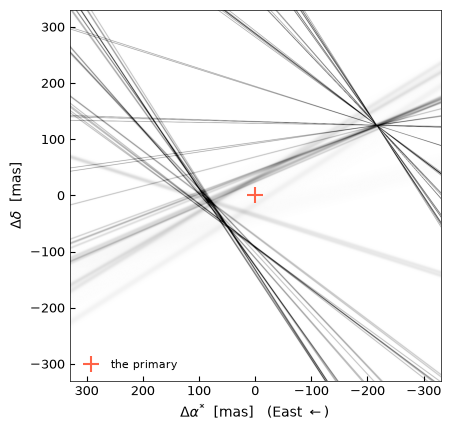

In [9]:
# the map: one sharp crossing far from the primary, and a broad group of lines near the primary
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.imshow(sky, origin="lower", extent=extent, cmap="gray_r", vmax=0.04 * sky.max())
ax.plot(0, 0, "+", color=ACCENT, ms=12, mew=1.5, label="the primary")
ax.set(xlim=(330, -330), ylim=(-330, 330), xlabel=EAST, ylabel=NORTH, aspect="equal")
ax.legend(loc="lower left", frameon=True, framealpha=0.9, edgecolor="none")
plt.tight_layout()
plt.show()

## 3. Why one seed is not enough

*Paper: Sect. 5.* The steps of notebook 2 (`dyn.clean_detection_set`) take the highest peak of the map and
keep the lines on its track. With two sources they return one of them, and they do not say that there is a
second one, or how many there are.

In [10]:
# notebook 2's steps on all the lines: one source comes back, and most lines are left without a source
# of its four returns, the covariance and the record are dropped (the two _)
theta_one, _, keep_one, _ = dyn.clean_detection_set(det.psi, det.tau, det.eta, det.sigma)

# ~keep_one inverts the mask: the lines that the fit did not keep

print(f"one source at ({theta_one[0]:+.1f}, {theta_one[1]:+.1f}) mas with {keep_one.sum()} of {keep_one.size} lines; "
      f"{np.sum(~keep_one)} lines are not explained")

one source at (-216.7, +124.9) mas with 40 of 69 lines; 29 lines are not explained


## 4. The threshold

*Paper: Sect. 5.1.* The search accepts a candidate when the joint fit improves by more than a threshold Λ_c.
`thr.lrt_threshold` gives the value that noise alone reaches in 1 % of the campaigns, for a candidate
searched anywhere in the field. It depends on the scan law, the instrument and the model, and not on the
noise level. Here the sources move (`tau` is given) and the primary is free.

In [11]:
# the threshold of the search: moving sources, the primary free, 1 % false additions
Lambda_c = thr.lrt_threshold(psi, inst, tau, eta0=eta0, free_primary=True)

print(f"Lambda_c = {Lambda_c:.1f}")

Lambda_c = 19.1


In [12]:
# the options at work: a search for sources at rest (no tau), and a false rate of 0.1 %
Lambda_c_rest = thr.lrt_threshold(psi, inst, eta0=eta0, free_primary=True)
Lambda_c_strict = thr.lrt_threshold(psi, inst, tau, eta0=eta0, free_primary=True, false_rate=0.001)

print(f"sources at rest:    {Lambda_c_rest:.1f}")
print(f"false rate 0.1 %:   {Lambda_c_strict:.1f}")

sources at rest:    17.1
false rate 0.1 %:   24.2


**Options of `thr.lrt_threshold`.** `tau`: give it for moving sources. `false_rate`: default 0.01.
`free_primary`: as in the fits. `mu_max`: the largest proper motion searched (default 10 mas/yr).
`half_size`, `origin_zone`: the field searched, and the zone about the primary that is excluded.

## 5. Rung 0, propose

*Paper: Sect. 5.1, stage 2.* The **pool** is the set of detections that no accepted source explains. At
rung 0 it is all the detections. `search.next_peak` returns the highest peak of the pool's map outside 30 mas
of the primary, the map's width there, and a mask of the pool's lines that pass through the peak. It is
`bp.map_peak` and `bp.peak_consistency` of notebook 2 in one call.

In [13]:
# rung 0, propose: the pool is every detection; its map's highest peak is the candidate
pool = np.ones(det.eta.size, bool)                       # True: the detection is in the pool
peak, width, through_peak = search.next_peak(det.psi[pool], det.eta[pool], det.sigma[pool])

print(f"candidate at ({peak[0]:+.0f}, {peak[1]:+.0f}) mas; {through_peak.sum()} of {pool.sum()} lines pass through it")

candidate at (-216, +126) mas; 39 of 69 lines pass through it


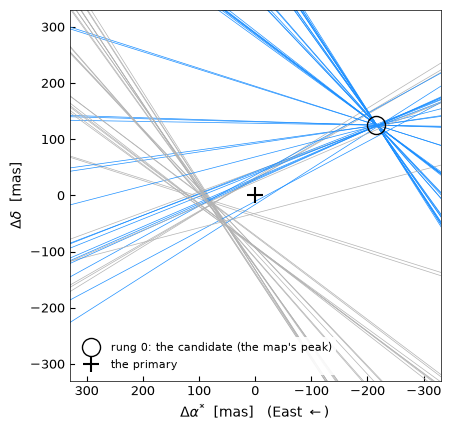

In [14]:
# rung 0 as a picture: the lines that pass through the peak (blue) and the other lines of the pool (gray)
fig, ax = plt.subplots(figsize=(4.6, 4.4))
for psi_line, eta_line, on_peak in zip(det.psi, det.eta, through_peak):
    if on_peak:
        colour = ACCENT_2
    else:
        colour = "0.7"
    # *sky_line(...): the two rows that sky_line returns, the ends' dra* and ddec, are the x and y of the line
    ax.plot(*sky_line(psi_line, eta_line), "-", color=colour, lw=0.5)
ax.plot(*peak, "o", mfc="none", mec="k", ms=13, label="rung 0: the candidate (the map's peak)")
ax.plot(0, 0, "+", color="k", ms=12, mew=1.5, label="the primary")
ax.set(xlim=(330, -330), ylim=(-330, 330), xlabel=EAST, ylabel=NORTH, aspect="equal")
ax.legend(loc="lower left", frameon=True, framealpha=0.9, edgecolor="none")
plt.tight_layout()
plt.show()

## 6. Rung 0, score

*Paper: Sect. 5.1, stage 2; Eq. 18.* `search.lambda_rung` makes two joint fits of **all the windows**
(`joint.fit_joint`, notebook 2, block 9): the accepted sources alone, and the accepted sources with the
candidate. The candidate starts at the peak, at rest. The score is

$$\Lambda = 2\,[\ln L(\text{with the candidate}) - \ln L(\text{without})] .$$

It returns Λ and the fit with the candidate.

**What is skipped.** In notebook 2 the peak was not given to the joint fit directly. It was refined first:
the sinogram fit with motion to the pool, and the test of every detection against the track (blocks 5 and
6 there), which gave a seed with a position and a motion. The search does not make this step. The joint fit
starts from the map's peak, with zero motion, and finds the position and the motion itself. Block 9 shows
what the skipped step would give.

In [15]:
# rung 0, score: no source is accepted yet ([]), so the fits are the primary alone and the primary + candidate
Lambda_0, fit_0 = search.lambda_rung(windows, psi, inst, sigma, [], peak, tau=tau, eta0=eta0, free_primary=True)

print(f"Lambda = {Lambda_0:.0f}")
print("the fit with the candidate, one block (dra*, ddec, mu_a*, mu_d) per row, the primary first:")
print(fit_0["theta"].reshape(-1, 4).round(2))            # reshape(-1, 4): one row of 4 per source

Lambda = 2783513
the fit with the candidate, one block (dra*, ddec, mu_a*, mu_d) per row, the primary first:
[[ 8.8000e+00 -3.3700e+00 -8.7000e-01 -9.1000e-01]
 [-2.1584e+02  1.2525e+02  9.0000e-02  9.0000e-02]]


## 7. Rung 0, test

*Paper: Sect. 5.1, stage 2.* The candidate is accepted when Λ is above Λ_c. Its position is then the one of
the joint fit, not the peak of the map.

In the fit of block 6 the primary is not at zero: (8.8, −3.4) mas, with a motion. The model of this rung has
no second companion, so the primary's block takes the light of the source that is not yet in the model. It
returns to zero at rung 1 (block 11).

In [16]:
# rung 0, test: accept when Lambda > Lambda_c; [-4:] takes the last block of the fit, the candidate's
block_0 = fit_0["theta"][-4:]
# the test itself: the candidate is accepted only when its Lambda is above the threshold. In the package's
# search a candidate below the threshold stops the search; here the notebook stops with an error
assert Lambda_0 > Lambda_c
accepted = [block_0[:2]]                                 # the list of accepted positions; [:2] is (dra*, ddec)

print(f"Lambda {Lambda_0:.0f} > Lambda_c {Lambda_c:.1f}: {Lambda_0 > Lambda_c} -> accepted, "
      f"at ({block_0[0]:+.2f}, {block_0[1]:+.2f}) mas, moving ({block_0[2]:+.2f}, {block_0[3]:+.2f}) mas/yr")

Lambda 2783513 > Lambda_c 19.1: True -> accepted, at (-215.84, +125.25) mas, moving (+0.09, +0.09) mas/yr


## 8. Rung 0, assign

*Paper: Sect. 5.1, stage 2; Eq. 17.* The lines of the accepted source leave the pool. A line belongs to the
source when it passes through the source's place **at the epoch of the line**: the test of notebook 2,
block 6. `ins.project_al` is Eq. 9, the along-scan position of a sky offset.

In [17]:
# rung 0, assign: each line's distance from the source's track at the line's own epoch, against max(3 sigma, w)
dra_at_epoch = block_0[0] + block_0[2] * det.tau         # the source's dra* at each line's epoch [mas]
ddec_at_epoch = block_0[1] + block_0[3] * det.tau        # its ddec at each line's epoch [mas]
track = ins.project_al(dra_at_epoch, ddec_at_epoch, det.psi)       # its position along each line's scan [mas]
belongs_0 = np.abs(det.eta - track) <= np.maximum(3.0 * det.sigma, width)
pool = pool & ~belongs_0                                 # the pool keeps the lines that do not belong

print(f"{belongs_0.sum()} lines belong to the accepted source; {pool.sum()} lines stay in the pool")

40 lines belong to the accepted source; 29 lines stay in the pool


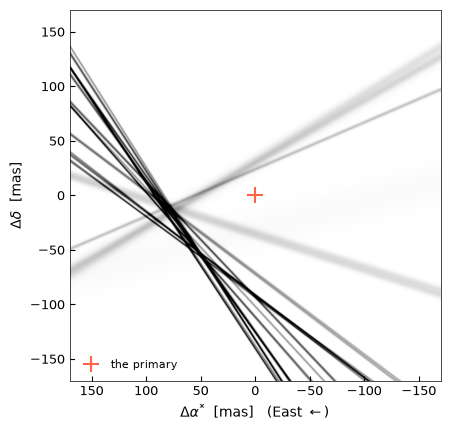

In [18]:
# the map of the pool: the lines that stay, all near the primary; [pool] takes the pool's detections
# the second and third returns of bp.backprojection_map (the axis and the extent) are dropped (the two _)
sky_pool, _, _ = bp.backprojection_map(det.psi[pool], det.eta[pool], det.sigma[pool], half_size=350.0, step=0.5)
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.imshow(sky_pool, origin="lower", extent=extent, cmap="gray_r", vmax=0.25 * sky_pool.max())
ax.plot(0, 0, "+", color=ACCENT, ms=12, mew=1.5, label="the primary")
ax.set(xlim=(170, -170), ylim=(-170, 170), xlabel=EAST, ylabel=NORTH, aspect="equal")
ax.legend(loc="lower left", frameon=True, framealpha=0.9, edgecolor="none")
plt.tight_layout()
plt.show()

The lines that stay do not cross at one point. This is the map of a source that moves (notebook 2, block 8,
left panel).

## 9. Rung 1, the skipped refinement, and the end of the search

*Paper: Sect. 5.1, 5.2.* The same four steps on the new pool. In the score, the source of rung 0 is in both
fits, and its position and motion are fitted again with the new candidate.

In [19]:
# rung 1, propose and score: the peak of the pool's map; the fits hold the accepted source, without and with it
pool_1 = pool.copy()                                     # the pool that rung 1 sees, kept for the cells below
peak_1, width_1, through_peak_1 = search.next_peak(det.psi[pool], det.eta[pool], det.sigma[pool])
Lambda_1, fit_1 = search.lambda_rung(windows, psi, inst, sigma, accepted, peak_1, tau=tau, eta0=eta0,
                                     free_primary=True)

print(f"candidate at ({peak_1[0]:+.0f}, {peak_1[1]:+.0f}) mas from {through_peak_1.sum()} of {pool.sum()} lines; "
      f"Lambda = {Lambda_1:.0f} against {Lambda_c:.1f}")

candidate at (+52, -52) mas from 14 of 29 lines; Lambda = 331758 against 19.1


In [20]:
# rung 1, test and assign: the candidate's block is the last one of the fit; its lines leave the pool
assert Lambda_1 > Lambda_c                               # the test of rung 1, as in rung 0
block_1 = fit_1["theta"][-4:]                            # the last four entries: (dra*, ddec, mu_a*, mu_d)
dra_at_epoch = block_1[0] + block_1[2] * det.tau         # the source's dra* at each line's epoch [mas]
ddec_at_epoch = block_1[1] + block_1[3] * det.tau        # its ddec at each line's epoch [mas]
track = ins.project_al(dra_at_epoch, ddec_at_epoch, det.psi)       # its position along each line's scan [mas]
belongs_1 = np.abs(det.eta - track) <= np.maximum(3.0 * det.sigma, width_1)
pool = pool & ~belongs_1

print(f"accepted at ({block_1[0]:+.2f}, {block_1[1]:+.2f}) mas, moving ({block_1[2]:+.2f}, {block_1[3]:+.2f}) mas/yr")
print(f"{belongs_1.sum()} lines belong to it; {pool.sum()} lines stay in the pool")

accepted at (+70.37, -25.87) mas, moving (-2.72, -7.46) mas/yr
30 lines belong to it; 1 lines stay in the pool


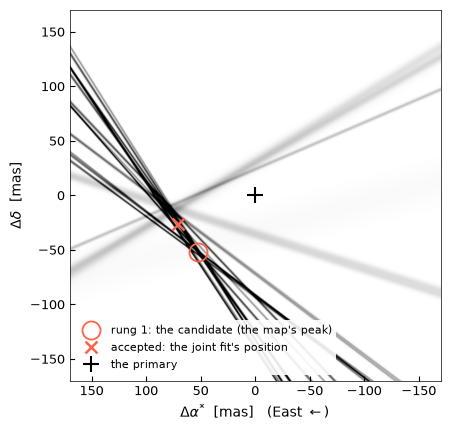

In [21]:
# rung 1 as a picture: the map of its pool, the candidate (the peak), and the position that the joint fit gives
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.imshow(sky_pool, origin="lower", extent=extent, cmap="gray_r", vmax=0.25 * sky_pool.max())
ax.plot(*peak_1, "o", mfc="none", mec=ACCENT, ms=13, mew=1.3, label="rung 1: the candidate (the map's peak)")
ax.plot(block_1[0], block_1[1], "x", color=ACCENT, ms=9, mew=1.8, label="accepted: the joint fit's position")
ax.plot(0, 0, "+", color="k", ms=12, mew=1.5, label="the primary")
ax.set(xlim=(170, -170), ylim=(-170, 170), xlabel=EAST, ylabel=NORTH, aspect="equal")
ax.legend(loc="lower left", frameon=True, framealpha=0.9, edgecolor="none")
plt.tight_layout()
plt.show()

The candidate is 32 mas from the position that the joint fit gives. The source of rung 1 moves, so its lines
never cross at one point: the map gave only a rough place, and the joint fit gave the position and the
motion.

**The skipped refinement, for comparison.** The steps of notebook 2 on the pool of rung 1
(`dyn.clean_detection_set`) give a seed with a motion, before any joint fit.

In [22]:
# the step that the search skips: the refined seed from the pool of rung 1 (notebook 2, blocks 3 to 7)
# [pool_1] takes the detections of that pool; the covariance and the record are dropped (the two _)
seed_1, _, keep_1, _ = dyn.clean_detection_set(det.psi[pool_1], det.tau[pool_1], det.eta[pool_1], det.sigma[pool_1])

# each vector holds (dra*, ddec, mu_a*, mu_d): entries 0 and 1 the position, 2 and 3 the motion
print(f"the peak (used by the search):   ({peak_1[0]:+.1f}, {peak_1[1]:+.1f}) mas, motion (0, 0)")
print(f"the refined seed (skipped):      ({seed_1[0]:+.1f}, {seed_1[1]:+.1f}) mas, "
      f"motion ({seed_1[2]:+.2f}, {seed_1[3]:+.2f}) mas/yr, "
      f"from {keep_1.sum()} of {pool_1.sum()} lines")
print(f"the joint fit of rung 1:         ({block_1[0]:+.1f}, {block_1[1]:+.1f}) mas, "
      f"motion ({block_1[2]:+.2f}, {block_1[3]:+.2f}) mas/yr")

the peak (used by the search):   (+52.0, -52.0) mas, motion (0, 0)
the refined seed (skipped):      (+71.4, -24.6) mas, motion (-3.37, -8.19) mas/yr, from 27 of 29 lines
the joint fit of rung 1:         (+70.4, -25.9) mas, motion (-2.72, -7.46) mas/yr


In [23]:
# the joint fit started from the refined seed in place of the peak: np.r_ joins the primary's block and source
# 1's block from rung 1's fit ([:8], the first two blocks) with the seed
start = np.r_[fit_1["theta"][:8], seed_1]
fit_seeded = joint.fit_joint(windows, psi, start, inst, sigma, tau=tau, eta0=eta0, free_primary=True)

largest_difference = np.abs(fit_seeded["theta"] - fit_1["theta"]).max()
print(f"largest difference between the two solutions: {largest_difference:.4f} (mas, mas/yr)")
print(f"chi2 from the peak {fit_1['chi2']:.2f}, from the refined seed {fit_seeded['chi2']:.2f}")

largest difference between the two solutions: 0.0001 (mas, mas/yr)
chi2 from the peak 813.80, from the refined seed 813.80


In this scene the two starts end at the same solution: the sources are well measured, and the joint fit
converges from 32 mas away. So the skipped step costs nothing here.

It is not always so. The refined seed is nearer the truth for a well-measured moving source. Near the
detection limit, the two starts can end in different solutions, and neither is better in every case
([`docs/routes.md`](../../docs/routes.md) gives the measurement). The search may get the refined seed, or
both starts, in a later version.

**The end.** The search stops when the pool has fewer than 3 lines (`search.GATE_MIN_DETECTIONS`), when its map has no
peak, when fewer than 3 lines pass through the peak, or when a candidate's Λ is below Λ_c. Here too few
lines are left: two sources, and the search is complete.

## 10. The search in one call

*Paper: Sect. 5.1.* `search.map_ladder` does blocks 4 to 9. It takes the detections (ψ, η, σ and their
epochs `det_tau`) and the windows. It returns a `MapLadder`: `positions` and `fluxes` of the accepted
sources from the last accepted fit, and `log`, one record per rung. `search.describe` prints the log.

In [24]:
# the whole search: the threshold is computed inside (bar="lrt", the default)
ladder = search.map_ladder(det.psi, det.eta, det.sigma, windows, psi, inst, sigma, tau=tau, det_tau=det.tau,
                           eta0=eta0, free_primary=True)

print(search.describe(ladder))
print(f"{ladder.n_sources} sources; each rung's record holds:", ", ".join(ladder.log[0]))

rung 0: peak (  -216,    126) from 39 of 69 lines;  Lambda 2783512.6 vs threshold  19.1  -> accepted  at (-215.8, 125.2)
rung 1: peak (    52,    -52) from 14 of 29 lines;  Lambda 331758.4 vs threshold  19.1  -> accepted  at (70.4, -25.9)
2 sources; each rung's record holds: rung, peak, width, n_pool, n_consistent, pool, Lambda, bar, fit, verdict, position


In [25]:
# the one call and the rungs by hand accept the same two sources, from the same last fit
assert ladder.n_sources == 2
blocks_by_hand = fit_1["theta"].reshape(-1, 4)           # one row of 4 per source, the primary first
positions_by_hand = blocks_by_hand[1:, :2]               # [1:, :2]: skip the primary's row, keep (dra*, ddec)
assert np.allclose(ladder.positions, positions_by_hand)
print("positions [mas]:", ladder.positions.round(2).tolist())

positions [mas]: [[-216.54, 125.05], [70.37, -25.87]]


**Options of `search.map_ladder`.**

| option | default | what it does |
|---|---|---|
| `tau`, `det_tau` | none | the epochs of the windows and of the detections: a search for moving sources. Give both, or neither (sources at rest) |
| `bar` | `"lrt"` | the threshold: the closed form of block 4, or a number (for example from a simulation) |
| `false_rate` | 0.01 | the false-addition rate of `bar="lrt"` |
| `max_sources` | none | a limit on the number of accepted sources |
| `free_primary` | False | fit the primary's offset and motion also |
| `mu_max` | 10 mas/yr | the limit on each proper motion in the scoring fits |
| `origin_zone` | 30 mas | no candidate is taken inside this radius of the primary |
| `k_sigma` | 3 | the width of the tests on the lines, in units of σ |
| `eta0` | none | the zero point of each window |

**Two details of the pool.** `search.map_ladder` builds the pool again after every accepted rung, from all
the detections and the latest fit of every accepted source; and its test adds the error of the fitted track
to the error of the line. Blocks 8 and 9 use the simpler test. The module's description
(`help(search)`) gives the equations, and [`docs/routes.md`](../../docs/routes.md) compares the search with
the steps of notebook 2.

## 11. The measurement

*Paper: Sect. 5.1, stage 3; Eq. 18.* The measurement is the joint fit of all the windows with all the
accepted sources. The last accepted rung already made this fit: it is `ladder.log[-1]["fit"]`, a result of
`joint.fit_joint` as in notebook 2, block 9.

In [26]:
# the last accepted rung's fit: one block per source, the primary first, in the order accepted
fit = ladder.log[-1]["fit"]                              # [-1]: the last record of the search's log
names = ("primary", "source 1", "source 2")

print(f"chi2 {fit['chi2']:.0f} for {windows.size} samples")
# reshape(-1, 4): one row of 4 per source; block is (dra*, ddec, mu_a*, mu_d) and err holds its four errors
for name, block, err in zip(names, fit["theta"].reshape(-1, 4), fit["sigma_theta"].reshape(-1, 4)):
    print(f"  {name:9s} ({block[0]:+8.2f}, {block[1]:+8.2f}) +- ({err[0]:.2f}, {err[1]:.2f}) mas, "
          f"mu ({block[2]:+5.2f}, {block[3]:+5.2f}) +- ({err[2]:.2f}, {err[3]:.2f}) mas/yr")

chi2 814 for 846 samples
  primary   (   +0.02,    +0.02) +- (0.04, 0.04) mas, mu (+0.01, +0.00) +- (0.02, 0.02) mas/yr
  source 1  ( -216.54,  +125.05) +- (0.06, 0.05) mas, mu (+0.05, +0.01) +- (0.04, 0.03) mas/yr
  source 2  (  +70.37,   -25.87) +- (0.17, 0.15) mas, mu (-2.72, -7.46) +- (0.08, 0.08) mas/yr


## 12. A source known from a catalogue

*Paper: Sect. 4.3, Eq. 19.* When another measurement gives a source's position, it enters the fit as a
Gaussian prior: `prior=(index, mean, sigma)`, the entries of the parameter vector that are constrained,
their values and their errors. The prior must come from a measurement that the windows did not make. Here
source 1 has a catalogue position with an error of 5 mas.

In [27]:
# truth: a catalogue position of C, drawn with an error of 5 mas (the truth is used to make it, and nowhere else)
# rng_catalogue: the generator of the catalogue error. Its seed is [the noise seed, the label 2 of this stream].
# It gives two normal numbers of sigma 5 mas: the errors in dra* and ddec
rng_catalogue = np.random.default_rng([SEED, 2])
catalogue_error = rng_catalogue.normal(0.0, 5.0, 2)
CATALOGUE_C = TRUE_C + catalogue_error

# [4:6]: entries 4 and 5 of theta, source 1's (dra*, ddec); entries 0 to 3 are the primary's block
print("catalogue position:", CATALOGUE_C.round(1).tolist(), "+- 5 mas;  source 1 in the fit:",
      fit["theta"][4:6].round(1).tolist())

catalogue position: [-220.8, 116.2] +- 5 mas;  source 1 in the fit: [-216.5, 125.1]


In [28]:
# the fit again from its own solution, with the prior on entries 4 and 5 of theta: source 1's (dra*, ddec)
# the prior is three arrays: the entries of theta it acts on, their means [mas], and their sigmas [mas]
# source 1 must be C for these entries to be C's: its fitted position is within 15 mas (three catalogue
# sigmas) of C's catalogue position; B is more than 200 mas from there
assert np.hypot(*(fit["theta"][4:6] - CATALOGUE_C)) < 15.0
prior = (np.array([4, 5]), CATALOGUE_C, np.array([5.0, 5.0]))
fit_prior = joint.fit_joint(windows, psi, fit["theta"], inst, sigma, tau=tau, eta0=eta0, free_primary=True,
                            prior=prior)

print(f"prior term of chi2: {fit_prior['chi2_prior']:.2f}")
print("source 1 without the prior:", fit["theta"][4:6].round(2).tolist(), "+-",
      fit["sigma_theta"][4:6].round(2).tolist())
print("source 1 with the prior:   ", fit_prior["theta"][4:6].round(2).tolist(), "+-",
      fit_prior["sigma_theta"][4:6].round(2).tolist())

prior term of chi2: 3.86
source 1 without the prior: [-216.54, 125.05] +- [0.06, 0.05]
source 1 with the prior:    [-216.54, 125.05] +- [0.06, 0.05]


The prior changes almost nothing here: the windows measure this source much better than 5 mas. A prior helps
when the windows measure a source badly, for example a neighbour at the edge of the windows.

## 13. The companions relative to the primary

*Paper: Sect. 5.2.* With a free primary, the physical quantity is a companion's block minus the primary's
block. The two are correlated, so the covariance of the difference comes from the full covariance of the
fit.

In [29]:
# a helper: source k's block minus the primary's block, and the covariance of that difference
def relative(fit, k):
    """(difference, covariance) of source k (1, 2, ...) relative to the primary (block 0).

    Inputs
        fit   a joint fit with the primary free (the dictionary that joint.fit_joint returns)
        k     the number of the source: 1 for the first accepted, 2 for the second
    Returns two things
        difference   source k's block minus the primary's: (dra*, ddec) [mas], (mu_a*, mu_d) [mas/yr]
        covariance   the 4 x 4 covariance of that difference"""
    n_theta = fit["theta"].size
    to_difference = np.zeros((4, n_theta))               # the matrix that takes theta to the difference
    to_difference[:, 4 * k:4 * k + 4] = np.eye(4)        # + the block of source k: columns 4k to 4k + 3
    to_difference[:, :4] -= np.eye(4)                    # - the block of the primary: columns 0 to 3
    difference = to_difference @ fit["theta"]            # @ is the matrix product
    theta_cov = fit["cov"][:n_theta, :n_theta]           # the parameters' part of the covariance, without the fluxes
    covariance = to_difference @ theta_cov @ to_difference.T
    return difference, covariance

In [30]:
# each source relative to the primary: separation, position angle, proper motion, and flux ratio
for k in (1, 2):                                         # k counts the accepted sources
    rel, rel_cov = relative(fit, k)
    # [:2] and [:2, :2]: the position entries of the difference and of its covariance
    rho, rho_err, pa, pa_err = joint.polar_elements(rel[:2], rel_cov[:2, :2])
    mu_err = np.sqrt(np.diag(rel_cov))[2:]               # [2:]: the errors of the two proper-motion entries
    flux_ratio = fit["flux"][k] / fit["flux"][0]         # source k's flux over the primary's (entry 0)
    print(f"source {k}: rho {rho:6.2f} +- {rho_err:.2f} mas, PA {pa:6.2f} +- {pa_err:.2f} deg, "
          f"mu ({rel[2]:+.2f}, {rel[3]:+.2f}) +- ({mu_err[0]:.2f}, {mu_err[1]:.2f}) mas/yr, "
          f"flux ratio {flux_ratio:.3f}")

source 1: rho 250.07 +- 0.05 mas, PA 300.00 +- 0.02 deg, mu (+0.04, +0.00) +- (0.05, 0.04) mas/yr, flux ratio 0.300
source 2: rho  74.96 +- 0.13 mas, PA 110.20 +- 0.16 deg, mu (-2.73, -7.47) +- (0.10, 0.09) mas/yr, flux ratio 0.200


## 14. The checks, and the truth

*Paper: Sect. 5.2.* Without the truth: χ² must be near the number of samples, and the primary's offset and
motion must agree with zero. Then the truth: source 1 is C and source 2 is B.

In [31]:
# without the truth: the misfit, and the primary against zero in units of its errors
n_free = fit["theta"].size + fit["flux"].size            # the fitted numbers: the parameters and the fluxes
primary_pull = fit["theta"][:4] / fit["sigma_theta"][:4]           # [:4]: the primary's block

print(f"chi2 / degrees of freedom = {fit['chi2'] / (windows.size - n_free):.2f}")
print("the primary's offset and motion, in units of their errors:", primary_pull.round(1).tolist())

chi2 / degrees of freedom = 0.98
the primary's offset and motion, in units of their errors: [0.4, 0.5, 0.5, 0.2]


In [32]:
# truth: each source's relative position and motion against the true values, in units of the errors
true_block_C = np.r_[TRUE_C, 0.0, 0.0]                   # (dra*, ddec, mu_a*, mu_d) of C, which is at rest
true_block_B = np.r_[TRUE_B, TRUE_PM_B]                  # the same for B; np.r_ joins position and motion
# the search accepted C first (source 1) and B second (source 2)
for k, name, true_block in ((1, "C", true_block_C), (2, "B", true_block_B)):
    rel, rel_cov = relative(fit, k)
    rel_err = np.sqrt(np.diag(rel_cov))                  # the errors of the four entries of the difference
    print(f"source {k} = {name}: fitted - true = {(rel - true_block).round(2).tolist()}, "
          f"in sigma {((rel - true_block) / rel_err).round(1).tolist()}")

source 1 = C: fitted - true = [-0.06, 0.04, 0.04, 0.0], in sigma [-0.7, 0.5, 0.8, 0.1]
source 2 = B: fitted - true = [-0.13, -0.23, 0.01, 0.05], in sigma [-0.7, -1.3, 0.1, 0.6]


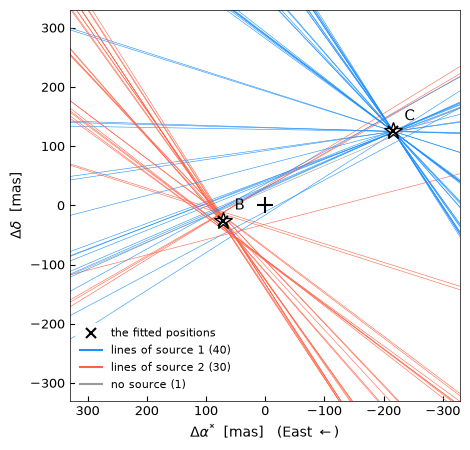

In [33]:
# truth: the detection of B and C as one picture. The lines by the source they were assigned to, the fitted
# positions (crosses) and the true ones (stars)
fig, ax = plt.subplots(figsize=(4.8, 4.6))
for psi_line, eta_line, is_0, is_1 in zip(det.psi, det.eta, belongs_0, belongs_1):
    # the line's colour: source 1's (rung 0) first, then source 2's (rung 1), then gray for no source
    if is_0:
        colour = ACCENT_2
    elif is_1:
        colour = ACCENT
    else:
        colour = "0.6"
    ax.plot(*sky_line(psi_line, eta_line), "-", color=colour, lw=0.4)
for true_position, colour, name in ((TRUE_C, ACCENT_2, "C"), (TRUE_B, ACCENT, "B")):
    ax.plot(*true_position, "*", mfc="white", mec="k", ms=13, zorder=5)
    ax.annotate(name, true_position, xytext=(8, 8), textcoords="offset points", fontsize=11)
# .T turns the rows (one per source) into two rows, all the dra* and all the ddec: the x and y of the crosses
ax.plot(*ladder.positions.T, "x", color="k", ms=7, mew=1.5, zorder=6, label="the fitted positions")
ax.plot([], [], "-", color=ACCENT_2, label=f"lines of source 1 ({belongs_0.sum()})")
ax.plot([], [], "-", color=ACCENT, label=f"lines of source 2 ({belongs_1.sum()})")
ax.plot([], [], "-", color="0.6", label=f"no source ({np.sum(~belongs_0 & ~belongs_1)})")
ax.plot(0, 0, "+", color="k", ms=12, mew=1.5)
ax.set(xlim=(330, -330), ylim=(-330, 330), xlabel=EAST, ylabel=NORTH, aspect="equal")
ax.legend(loc="lower left", frameon=True, framealpha=0.9, edgecolor="none")
plt.tight_layout()
plt.show()

This is one noise draw. When a check fails, the notebooks in [`scene/limitations/`](../scene/limitations/)
show each assumption broken, and what each step then returns.

## Where to go from here

- The paper's own notebook of this scene, with the numbers of Sect. 5.2 and Figure 4:
  [`paper/fig4_contaminated_binary.ipynb`](../paper/fig4_contaminated_binary.ipynb).
- The two ways from the detections to the joint fit, side by side: [`docs/routes.md`](../../docs/routes.md).
- The conventions and every public function: [`docs/conventions.md`](../../docs/conventions.md),
  [`docs/open_api.md`](../../docs/open_api.md).